# Decode the Bioreactor — 03 Hybrid: base model + ML correction
**Idea**: keep a base prediction and let a small ML model learn what the base gets wrong:

  y_hat(t) = base(t) · exp(g(features))

- **base** = mechanistic model (from notebook 02) **or** the median training curve
- **g** learns the *relative* error of the base (log ratio, consistent with MAPE) from: time, day-0 values, cumulative feed volumes up to t, volume at t, base prediction. All are known for a test batch.
- **methods**: `ridge_day` (one ridge regression per state and day; linear, interpretable) and `gbr` (shallow gradient-boosted trees; non-linear).
- Corrections are clipped to ±40 %.

Variants compared on the same CV folds: `median+ridge_day`, `median+gbr`, `mech+ridge_day`, `mech+gbr` (plus the plain bases), each also with **`+feeds`** = extra state-specific inputs:
- **vcd / tcd**: feed B since the previous sample and right after the sample (feed B may be dosed in proportion to the cell count),
- **substrate**: substrate supplied by the feeds since the previous sample / right after / in total, in g/L (mass balance, feed concentrations Sb, Ss from the mechanistic fit), plus substrate-bolus count and time since the last bolus,
- **byproduct**: feed C volume and number of feed-C events in the last day / right after the sample (feed C looks like on-demand dosing, e.g. base for pH control → a sensor for the acid the cells produce).
Feeds right after a sample are known for test batches (the full feed schedule is given).
Code: `src/bioreactor/hybrid.py`, metrics: `src/bioreactor/evaluate.py`.

**Leakage note**: in each fold the mechanistic parameters and the ML correction are fitted on the training batches only. The ML is trained on the mechanistic model's *in-sample* residuals, which are a bit smaller than on new batches — CV tells the honest result.

In [5]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from bioreactor.data import load, to_arrays, STATES
from bioreactor.model import predict_at_obs, NAMES
from bioreactor.fit import fit_staged, initial_from_data
from bioreactor.hybrid import median_curve_preds, feature_table, feature_columns, ResidualCorrector, to_list
from bioreactor.evaluate import metrics, mape_row

df, tmpl, train_ids, test_ids = load(ROOT / "data")
splits = pd.read_csv(ROOT / "outputs" / "splits.csv")
dev_ids = splits.query("role == 'dev'").batch_id.tolist()
hold_ids = splits.query("role == 'holdout'").batch_id.tolist()
fold_of = splits.query("role == 'dev'").set_index("batch_id").fold.to_dict()

# mechanistic fit settings (same meaning as in notebook 02)
MAX_NFEV_STAGE, MAX_NFEV, N_STARTS = 20, 60, 1
FIT_KW = dict(residual="log", loss="soft_l1", f_scale=0.1)
METHODS = ["ridge_day", "gbr"]
EXTRA_OPTIONS = [False, True]   # without / with the extra "+feeds" inputs
CACHE = ROOT / "outputs" / "params_cache"; CACHE.mkdir(parents=True, exist_ok=True)
USE_CACHE = True   # reuse mechanistic parameters already fitted for the same training set

In [6]:
def mech_params(ids, tag):
    """Fit the mechanistic model on `ids` (staged fit), or load it from the cache."""
    f = CACHE / f"{tag}.csv"
    if USE_CACHE and f.exists():
        s = pd.read_csv(f, index_col=0).iloc[:, 0]
        if list(s.index) == NAMES:
            print(f"[{tag}] mechanistic parameters loaded from cache"); return s.values
    t0 = time.time()
    p, _ = fit_staged(to_arrays(df, ids), None, p_init=initial_from_data(df, ids),
                      max_nfev_stage=MAX_NFEV_STAGE, max_nfev_final=MAX_NFEV,
                      n_starts=N_STARTS, verbose=False, **FIT_KW)
    pd.Series(p, index=NAMES).to_csv(f); print(f"[{tag}] mechanistic fit {time.time()-t0:.0f} s")
    return p

def evaluate_split(tr_ids, va_ids, tag, methods=METHODS, extras=EXTRA_OPTIONS):
    """Fit everything on tr_ids, evaluate all variants on va_ids. Returns (MAPE table, objects)."""
    a_tr, a_va = to_arrays(df, tr_ids), to_arrays(df, va_ids)
    p = mech_params(tr_ids, tag)
    bases = {"median": (median_curve_preds(df, tr_ids, a_tr), median_curve_preds(df, tr_ids, a_va)),
             "mech":   (predict_at_obs(p, a_tr), predict_at_obs(p, a_va))}
    rows, objs = {}, {"p": p, "a_va": a_va}
    for bname, (b_tr, b_va) in bases.items():
        rows[bname] = mape_row(a_va, b_va)
        objs[bname] = (None, b_va)
        # p is passed for both bases: it only provides feed concentrations for the S_supply features
        F_tr, F_va = feature_table(df, a_tr, b_tr, p=p), feature_table(df, a_va, b_va, p=p)
        objs[f"F_tr_{bname}"] = F_tr
        for m in methods:
            for ex in extras:
                name = f"{bname}+{m}" + ("+feeds" if ex else "")
                corr = ResidualCorrector(m, extra=ex).fit(F_tr)
                pred = to_list(F_va, corr.predict(F_va), a_va)
                rows[name] = mape_row(a_va, pred)
                objs[name] = (corr, pred)
    return pd.DataFrame(rows).T, objs

## 1. One fold (quick look)
MAPE % on the validation fold for every variant. The first run fits the mechanistic model for this fold (a few minutes); later runs load it from `outputs/params_cache/`.

In [7]:
FOLD = 0
tr_ids = [b for b in dev_ids if fold_of[b] != FOLD]
va_ids = [b for b in dev_ids if fold_of[b] == FOLD]
t0 = time.time()
tab, objs = evaluate_split(tr_ids, va_ids, tag=f"fold{FOLD}")
print(f"{time.time()-t0:.0f} s")
tab.round(2).sort_values("all")

[fold0] mechanistic parameters loaded from cache
4 s


,vcd,tcd,substrate,byproduct,all
median+gbr+feeds,7.03,7.00,8.48,10.58,8.28
mech+gbr+feeds,6.96,6.74,7.75,11.73,8.30
median+gbr,7.07,6.98,8.78,10.44,8.32
median+ridge_day+feeds,6.70,6.68,8.63,11.33,8.34
median+ridge_day,6.84,6.82,9.43,10.47,8.39
mech+ridge_day,6.79,6.71,9.22,11.35,8.52
mech+gbr,6.95,6.77,8.74,11.86,8.58
mech+ridge_day+feeds,6.90,6.75,9.17,12.01,8.71
median,8.16,8.11,9.97,11.93,9.54
mech,10.36,11.10,13.51,16.99,12.99


### Do the extra feed inputs carry signal?
Spearman correlation, per day, between each extra input and what the mechanistic base gets wrong, log(observed / mech), on the training batches of this fold. Consistent colours across days = real signal; random noise = nothing to learn.

c:\Users\karimi\anaconda3\lib\site-packages\scipy\stats\_stats_py.py:4916: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))
c:\Users\karimi\anaconda3\lib\site-packages\scipy\stats\_stats_py.py:4916: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))
c:\Users\karimi\anaconda3\lib\site-packages\scipy\stats\_stats_py.py:4916: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))
c:\Users\karimi\anaconda3\lib\site-packages\scipy\stats\_stats_py.py:4916: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  warnings.warn(stats.ConstantInputWarning(warn_msg))


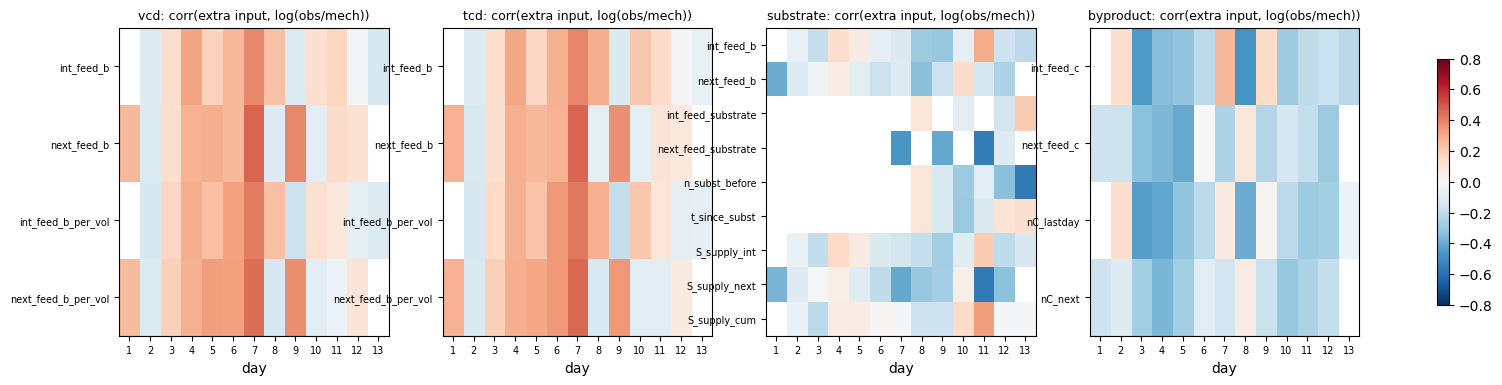

In [8]:
from bioreactor.hybrid import EXTRA
F_tr_m = objs["F_tr_mech"]
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, s in zip(ax, STATES):
    resid = np.log(F_tr_m[f"obs_{s}"]) - np.log(F_tr_m[f"base_{s}"])
    cols = [c for c in EXTRA[s] if c in F_tr_m.columns]
    R = pd.DataFrame({c: [F_tr_m.loc[F_tr_m.day == d, c].corr(resid[F_tr_m.day == d], method="spearman")
                          for d in sorted(F_tr_m.day.unique())] for c in cols},
                     index=sorted(F_tr_m.day.unique()))
    im = a.imshow(R.T.values, aspect="auto", cmap="RdBu_r", vmin=-0.8, vmax=0.8)
    a.set_yticks(range(len(cols))); a.set_yticklabels(cols, fontsize=7)
    a.set_xticks(range(len(R))); a.set_xticklabels(R.index, fontsize=7); a.set_xlabel("day")
    a.set_title(f"{s}: corr(extra input, log(obs/mech))", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.8); plt.show()

Where do the variants miss? Mean absolute % error by day on the validation fold.

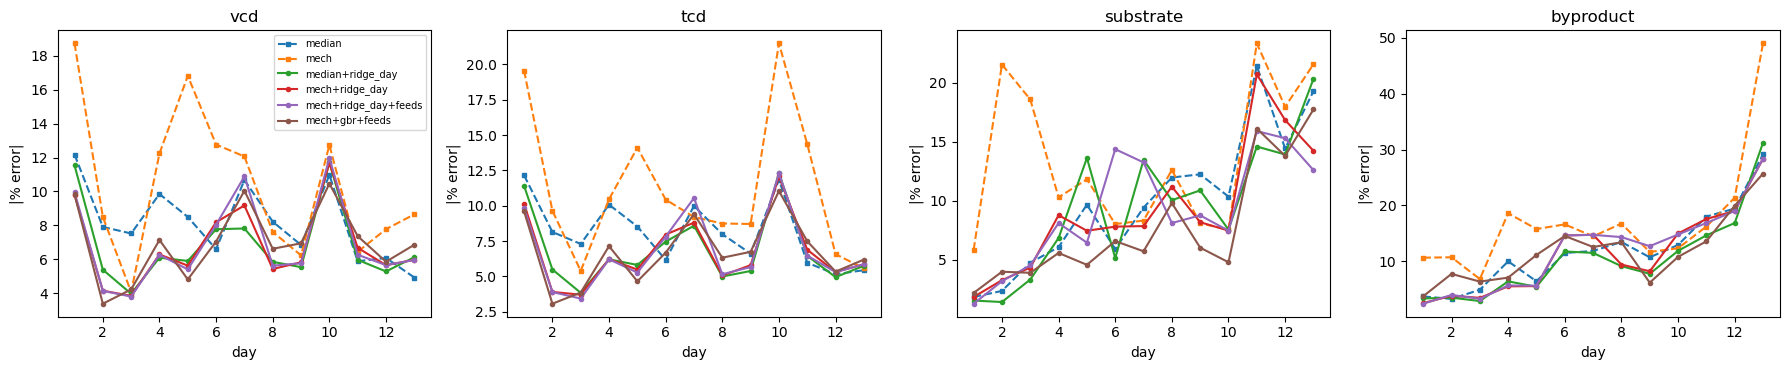

In [9]:
def abs_err_by_day(arr, preds):
    Y = np.vstack(arr.obs_y); Yh = np.vstack(preds); T = np.round(np.concatenate(arr.obs_t)).astype(int)
    e = pd.DataFrame(100 * np.abs(Yh - Y) / Y, columns=STATES); e["day"] = T
    return e.groupby("day").mean()

SHOW = ["median", "mech", "median+ridge_day", "mech+ridge_day", "mech+ridge_day+feeds", "mech+gbr+feeds"]
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
for name in SHOW:
    e = abs_err_by_day(objs["a_va"], objs[name][1])
    for a, s in zip(ax, STATES):
        a.plot(e.index, e[s], "o-" if "+" in name else "s--", ms=3, label=name)
for a, s in zip(ax, STATES):
    a.set_title(s); a.set_xlabel("day"); a.set_ylabel("|% error|")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

### Interpretation
**Ridge (per day)**: standardised coefficients — how much each input shifts the prediction (log units ≈ relative change) per 1 std of that input, by day. Shown for the median base: the coefficients then describe directly how inputs move a batch away from the typical curve.

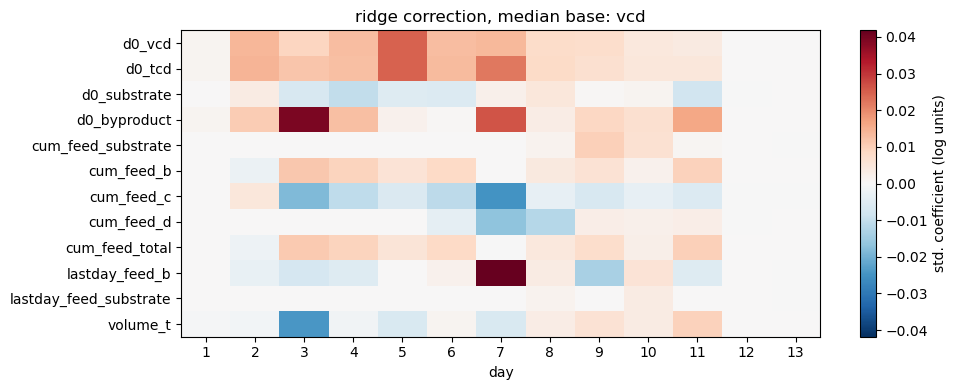

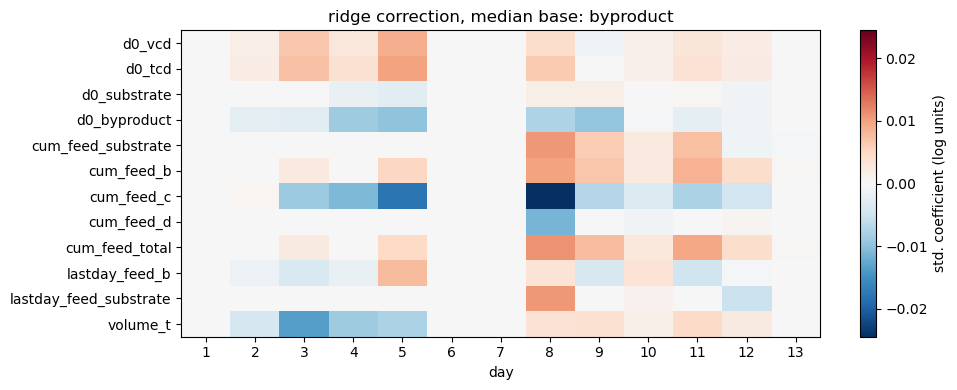

In [10]:
corr_r = objs["median+ridge_day"][0]
for s in ["vcd", "byproduct"]:
    C = corr_r.ridge_coefficients(s)
    C = C[[c for c in C.columns if not c.startswith("logbase_")]]   # base is constant per day for the median base
    plt.figure(figsize=(10, 4)); lim = np.abs(C.values).max()
    plt.imshow(C.values.T, aspect="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
    plt.yticks(range(C.shape[1]), C.columns); plt.xticks(range(C.shape[0]), C.index); plt.xlabel("day")
    plt.colorbar(label="std. coefficient (log units)"); plt.title(f"ridge correction, median base: {s}")
    plt.tight_layout(); plt.show()

In [11]:
# gradient boosting: feature importances per state (mechanistic base)
corr_g = objs["mech+gbr"][0]
imp = pd.DataFrame({s: corr_g.models[s].feature_importances_ for s in STATES}, index=corr_g.cols_["vcd"])
imp.sort_values("vcd", ascending=False).round(3)

,vcd,tcd,substrate,byproduct
volume_t,0.186,0.123,0.008,0.002
d0_tcd,0.132,0.131,0.057,0.060
cum_feed_b,0.111,0.049,0.026,0.024
t,0.089,0.046,0.044,0.058
logbase_byproduct,0.078,0.351,0.123,0.207
cum_feed_total,0.078,0.047,0.012,0.013
logbase_tcd,0.067,0.018,0.029,0.030
d0_byproduct,0.055,0.057,0.085,0.078
logbase_substrate,0.041,0.032,0.132,0.031
cum_feed_c,0.036,0.005,0.028,0.129


## 2. 5-fold cross-validation (all variants)
The honest comparison. Each fold: mechanistic fit + ML fit on its training batches only. Mechanistic parameters are cached per fold, so re-runs (e.g. after changing the ML part) are fast.

In [13]:
RUN_CV = True
if RUN_CV:
    tabs = []
    for f in range(5):
        tr_ = [b for b in dev_ids if fold_of[b] != f]; va_ = [b for b in dev_ids if fold_of[b] == f]
        t_, _ = evaluate_split(tr_, va_, tag=f"fold{f}")
        tabs.append(t_.assign(fold=f)); print(f"fold {f}: pooled MAPE", t_["all"].round(2).to_dict())
    cv = pd.concat(tabs).rename_axis("variant").reset_index()
    summary = cv.groupby("variant")[STATES + ["all"]].agg(["mean", "std"]).round(2)
    display(summary.sort_values(("all", "mean")))

[fold0] mechanistic parameters loaded from cache
fold 0: pooled MAPE {'median': 9.54, 'median+ridge_day': 8.39, 'median+ridge_day+feeds': 8.34, 'median+gbr': 8.32, 'median+gbr+feeds': 8.28, 'mech': 12.99, 'mech+ridge_day': 8.52, 'mech+ridge_day+feeds': 8.71, 'mech+gbr': 8.58, 'mech+gbr+feeds': 8.3}
[fold1] mechanistic fit 80 s
fold 1: pooled MAPE {'median': 10.38, 'median+ridge_day': 9.62, 'median+ridge_day+feeds': 8.78, 'median+gbr': 9.93, 'median+gbr+feeds': 9.54, 'mech': 13.14, 'mech+ridge_day': 9.1, 'mech+ridge_day+feeds': 8.97, 'mech+gbr': 9.64, 'mech+gbr+feeds': 9.06}
[fold2] mechanistic fit 79 s
fold 2: pooled MAPE {'median': 10.07, 'median+ridge_day': 9.48, 'median+ridge_day+feeds': 8.85, 'median+gbr': 10.66, 'median+gbr+feeds': 10.11, 'mech': 13.78, 'mech+ridge_day': 10.46, 'mech+ridge_day+feeds': 10.0, 'mech+gbr': 11.29, 'mech+gbr+feeds': 10.85}
[fold3] mechanistic fit 74 s
fold 3: pooled MAPE {'median': 12.0, 'median+ridge_day': 11.55, 'median+ridge_day+feeds': 11.27, 'media

vcd          tcd       substrate       byproduct  \
                         mean   std   mean   std      mean   std      mean   
variant                                                                      
median+ridge_day+feeds   7.73  0.85   7.68  0.92      9.62  1.49     12.75   
median+gbr+feeds         7.17  0.78   7.03  0.81     11.10  1.84     13.86   
median+ridge_day         7.74  0.83   7.72  0.89     11.16  1.56     12.68   
mech+gbr+feeds           7.31  0.61   7.18  0.79     10.53  1.76     14.38   
mech+ridge_day+feeds     7.92  0.92   7.84  1.03     10.45  1.55     13.32   
mech+ridge_day           7.92  1.03   7.86  1.10     10.92  1.83     13.10   
median+gbr               7.20  0.83   7.08  0.89     12.17  2.07     13.87   
mech+gbr                 7.33  0.72   7.21  0.85     11.84  1.89     14.32   
median                   8.58  0.55   8.65  0.59     11.69  1.40     13.04   
mech                    10.77  0.50  11.62  0.72     15.09  1.68     16.79   

                                all        
                         std   mean   std  
variant                                    
median+ridge_day+feeds  2.91   9.44  1.19  
median+gbr+feeds        2.49   9.79  1.04  
median+ridge_day        3.06   9.82  1.15  
mech+gbr+feeds          2.51   9.85  1.35  
mech+ridge_day+feeds    2.63   9.88  1.14  
mech+ridge_day          2.69   9.95  1.17  
median+gbr              2.56  10.08  1.14  
mech+gbr                2.43  10.18  1.36  
median                  2.79  10.49  0.92  
mech                    2.66  13.57  0.52

## 3. Hold-out check — run ONCE, after choosing the variant from CV
Fit on all 39 dev batches, evaluate on the 10 hold-out batches.

In [12]:
RUN_HOLDOUT = True
if RUN_HOLDOUT:
    tab_h, objs_h = evaluate_split(dev_ids, hold_ids, tag="dev_all")
    display(tab_h.round(2).sort_values("all"))

[dev_all] mechanistic parameters loaded from cache


,vcd,tcd,substrate,byproduct,all
median+gbr+feeds,6.10,6.03,7.94,8.34,7.10
mech+gbr+feeds,6.09,6.10,7.76,8.82,7.19
median+ridge_day+feeds,6.79,6.78,6.90,8.40,7.22
mech+ridge_day+feeds,6.94,6.96,6.41,8.62,7.23
mech+ridge_day,6.89,6.98,7.32,8.58,7.44
median+gbr,6.15,6.09,9.20,8.37,7.45
mech+gbr,6.32,6.17,8.64,8.68,7.45
median+ridge_day,6.76,6.70,8.65,8.29,7.60
median,8.94,8.99,10.37,8.54,9.21
mech,10.76,10.93,12.50,12.32,11.63


## 4. Final: fit on all 49 batches → submission
Pick the variant (best CV), then predict the 12 test batches → `outputs/submission_hybrid_<base>_<method>.csv`.

In [ ]:
RUN_FINAL = False
BASE, METHOD = "mech", "ridge_day"     # set from the CV result
EXTRA = True                           # with the extra "+feeds" inputs?
if RUN_FINAL:
    a_all = to_arrays(df, train_ids)
    a_test = to_arrays(df, test_ids, sample_mask="predict")
    p_all = mech_params(train_ids, tag="all49")      # also needed for the S_supply features
    if BASE == "mech":
        b_all, b_test = predict_at_obs(p_all, a_all), predict_at_obs(p_all, a_test)
    else:
        b_all, b_test = median_curve_preds(df, train_ids, a_all), median_curve_preds(df, train_ids, a_test)
    corr = ResidualCorrector(METHOD, extra=EXTRA).fit(feature_table(df, a_all, b_all, p=p_all))
    F_test = feature_table(df, a_test, b_test, p=p_all)
    preds = to_list(F_test, corr.predict(F_test), a_test)
    failed = [b for b, y in zip(a_test.ids, preds) if np.isnan(y).any()]
    assert not failed, f"NaN predictions for {failed}"

    pred_of = {b: (ts, ys) for b, ts, ys in zip(a_test.ids, a_test.obs_t, preds)}
    sub = tmpl.copy(); sub[STATES] = sub[STATES].astype(float)   # template columns are int zeros
    for b, g in sub.groupby("batch_id", sort=False):
        ts, ys = pred_of[b]; order = np.argsort(ts)
        assert len(g) == len(ts) and np.allclose(np.sort(g.elapsed_time.values), ts[order], atol=1e-3), b
        sub.loc[g.sort_values("elapsed_time").index, STATES] = ys[order]
    assert sub[STATES].notna().all().all()
    out = ROOT / "outputs" / f"submission_hybrid_{BASE}_{METHOD}{'_feeds' if EXTRA else ''}.csv"
    sub.to_csv(out, index=False); print("written", out)
    display(sub.head())